In [1]:
import sys; sys.path.append("..")
import numpy as np, matplotlib.pyplot as plt
from data import get_splits, one_hot
from metrics import evaluate, Timer
from softmax import train, predict, full_eval, loss_and_grad

d = get_splits()
Xtr, ytr, Xva, yva = d["X_train"], d["y_train"], d["X_val"], d["y_val"]

In [2]:
lrs = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]
runs = {}
for lr in lrs:
    W, b, h = train(Xtr, ytr, Xva, yva, lr=lr, epochs=30, batch_size=128)
    runs[lr] = (W, b, h)
    print(f"lr={lr}: val acc {h['val_acc'][-1]*100:.2f}% | train loss {h['train_loss'][-1]:.4f} | val loss {h['val_loss'][-1]:.4f}")

lr=0.01: val acc 90.36% | train loss 0.3357 | val loss 0.3530
lr=0.05: val acc 91.71% | train loss 0.2761 | val loss 0.3078
lr=0.1: val acc 92.02% | train loss 0.2604 | val loss 0.2997
lr=0.5: val acc 91.86% | train loss 0.2375 | val loss 0.3037
lr=1.0: val acc 91.43% | train loss 0.2381 | val loss 0.3239
lr=2.0: val acc 90.10% | train loss 0.2831 | val loss 0.4087


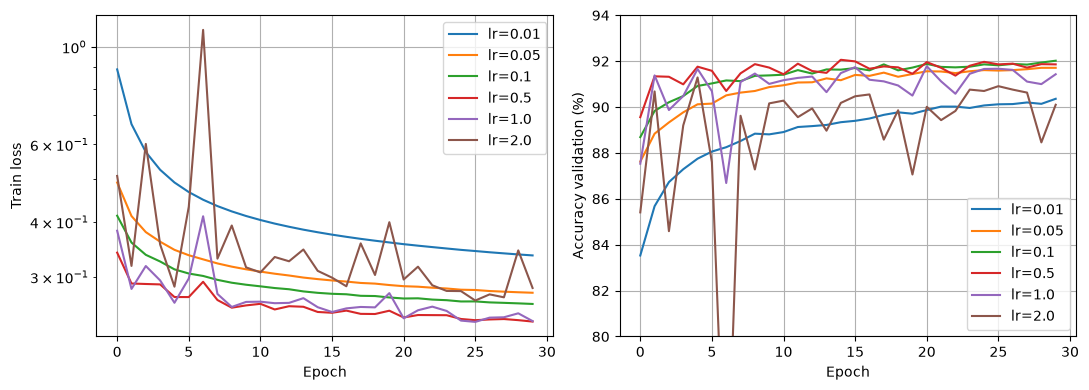

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lr, (W, b, h) in runs.items():
    ax[0].plot(h["train_loss"], label=f"lr={lr}")
    ax[1].plot(np.array(h["val_acc"]) * 100, label=f"lr={lr}")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Train loss"); ax[0].set_yscale("log"); ax[0].legend(); ax[0].grid(True)
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy validation (%)"); ax[1].set_ylim(80, 94); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.savefig("../report/softmax_lr.png", dpi=150); plt.show()

lr tốt nhất: 0.1
fit 2.67s | predict(val) 0.003s
train: acc 92.87% | P 92.79% | R 92.78% | F1 92.78%
val: acc 92.02% | P 91.92% | R 91.90% | F1 91.90%


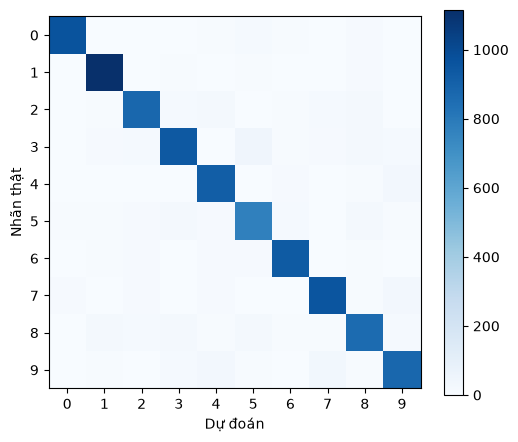

In [4]:
best_lr = max(runs, key=lambda lr: runs[lr][2]["val_acc"][-1])
print("lr tốt nhất:", best_lr)

# Đo thời gian huấn luyện thật (không ghi loss mỗi epoch)
with Timer() as t_fit:
    W, b, _ = train(Xtr, ytr, Xva, yva, lr=best_lr, epochs=30, batch_size=128, track=False)
with Timer() as t_pred:
    p_va = predict(W, b, Xva)
p_tr = predict(W, b, Xtr)

r_tr, r_va = evaluate(ytr, p_tr), evaluate(yva, p_va)
print(f"fit {t_fit.seconds:.2f}s | predict(val) {t_pred.seconds:.3f}s")
for name, r in [("train", r_tr), ("val", r_va)]:
    print(f"{name}: acc {r['accuracy']*100:.2f}% | P {r['precision_macro']*100:.2f}% | R {r['recall_macro']*100:.2f}% | F1 {r['f1_macro']*100:.2f}%")

# Confusion matrix validation
plt.figure(figsize=(6, 5)); plt.imshow(r_va["confusion_matrix"], cmap="Blues"); plt.colorbar()
plt.xlabel("Dự đoán"); plt.ylabel("Nhãn thật"); plt.xticks(range(10)); plt.yticks(range(10))
plt.savefig("../report/softmax_confusion_val.png", dpi=150); plt.show()

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from data import one_hot

# Tạo mô hình sklearn rồi ghi đè tham số bằng của mình
sk = LogisticRegression()
sk.fit(Xtr[:2000], ytr[:2000])                 # chỉ để khởi tạo, vài giây
sk.coef_ = W.T.astype(np.float64)
sk.intercept_ = b.astype(np.float64)

my_loss, my_acc = full_eval(W, b, Xva.astype(np.float64), yva, one_hot(yva).astype(np.float64))
sk_loss = log_loss(yva, sk.predict_proba(Xva.astype(np.float64)), labels=np.arange(10))
print("loss của mình   :", my_loss)
print("log_loss sklearn:", sk_loss)
print("dự đoán trùng nhau:", (sk.predict(Xva.astype(np.float64)) == predict(W, b, Xva)).mean())

loss của mình   : 0.29973336034507736
log_loss sklearn: 0.29973336034507736
dự đoán trùng nhau: 1.0


c:\DOAN1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [8]:
import time
t0 = time.perf_counter()
sk2 = LogisticRegression(penalty=None, max_iter=50).fit(Xtr, ytr)
print("thời gian:", round(time.perf_counter() - t0, 1), "s")
print("val acc sklearn (50 vòng lbfgs):", (sk2.predict(Xva) == yva).mean() * 100)

c:\DOAN1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


thời gian: 73.1 s
val acc sklearn (50 vòng lbfgs): 91.79


c:\DOAN1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
